In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

# import os
# for dirname, _, filenames in os.walk('/kaggle/input'):
#     for filename in filenames:
#         print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [2]:
import os

for root, dirs, files in os.walk("/kaggle/input"):
    print(root)

/kaggle/input
/kaggle/input/datasets
/kaggle/input/datasets/mariaherrerot
/kaggle/input/datasets/mariaherrerot/aptos2019
/kaggle/input/datasets/mariaherrerot/aptos2019/val_images
/kaggle/input/datasets/mariaherrerot/aptos2019/val_images/val_images
/kaggle/input/datasets/mariaherrerot/aptos2019/train_images
/kaggle/input/datasets/mariaherrerot/aptos2019/train_images/train_images
/kaggle/input/datasets/mariaherrerot/aptos2019/test_images
/kaggle/input/datasets/mariaherrerot/aptos2019/test_images/test_images
/kaggle/input/datasets/mariaherrerot/ddrdataset
/kaggle/input/datasets/mariaherrerot/ddrdataset/DR_grading
/kaggle/input/datasets/mariaherrerot/ddrdataset/DR_grading/DR_grading


In [3]:
import os

BASE_PATH = "/kaggle/input/datasets/mariaherrerot/aptos2019"

print(os.listdir(BASE_PATH))

['val_images', 'train_images', 'valid.csv', 'test.csv', 'train_1.csv', 'test_images']


In [4]:
for root, dirs, files in os.walk(BASE_PATH):
    for file in files:
        if file.endswith(".csv"):
            print(os.path.join(root, file))

/kaggle/input/datasets/mariaherrerot/aptos2019/valid.csv
/kaggle/input/datasets/mariaherrerot/aptos2019/test.csv
/kaggle/input/datasets/mariaherrerot/aptos2019/train_1.csv


In [5]:
TRAIN_DIR = "/kaggle/input/datasets/mariaherrerot/aptos2019/train_images/train_images"

In [6]:
from PIL import Image
import os

files = os.listdir(TRAIN_DIR)

print("Number of images:", len(files))
print("First 5:", files[:5])

Number of images: 2930
First 5: ['6dcde47060f9.png', 'b49b2fac2514.png', 'af6166d57f13.png', '8d13c46e7d75.png', 'c3b15bf9b4bc.png']


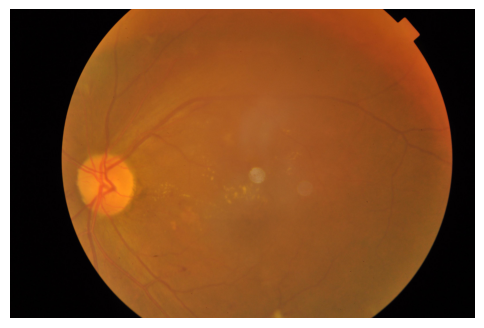

In [7]:
import matplotlib.pyplot as plt
from PIL import Image
import os

image_name = files[0]

image = Image.open(
    os.path.join(TRAIN_DIR, image_name)
)

plt.figure(figsize=(6, 6))
plt.imshow(image)
plt.axis("off")
plt.show()

In [8]:
import pandas as pd

TRAIN_CSV = "/kaggle/input/datasets/mariaherrerot/aptos2019/train_1.csv"

df = pd.read_csv(TRAIN_CSV)

print(df.head())
print()
print("Shape:", df.shape)
print()
print("Columns:", df.columns.tolist())

        id_code  diagnosis
0  1ae8c165fd53          2
1  1b329a127307          1
2  1b32e1d775ea          4
3  1b3647865779          0
4  1b398c0494d1          0

Shape: (2930, 2)

Columns: ['id_code', 'diagnosis']


In [9]:
print(df["diagnosis"].value_counts().sort_index())

diagnosis
0    1434
1     300
2     808
3     154
4     234
Name: count, dtype: int64


In [10]:
TRAIN_DIR = "/kaggle/input/datasets/mariaherrerot/aptos2019/train_images/train_images"

In [11]:
import os

print("Images:", len(os.listdir(TRAIN_DIR)))
print("CSV rows:", len(df))

print("\nFirst CSV ID:")
print(df.iloc[0]["id_code"])

print("\nFirst image:")
print(os.listdir(TRAIN_DIR)[0])

Images: 2930
CSV rows: 2930

First CSV ID:
1ae8c165fd53

First image:
6dcde47060f9.png


In [12]:
import os
from PIL import Image

# Take the first row from the CSV
row = df.iloc[0]

image_id = row["id_code"]
label = row["diagnosis"]

image_path = os.path.join(
    TRAIN_DIR,
    image_id + ".png"
)

print("Image ID:", image_id)
print("Diagnosis:", label)
print("Image path:", image_path)
print("Exists:", os.path.exists(image_path))

Image ID: 1ae8c165fd53
Diagnosis: 2
Image path: /kaggle/input/datasets/mariaherrerot/aptos2019/train_images/train_images/1ae8c165fd53.png
Exists: True


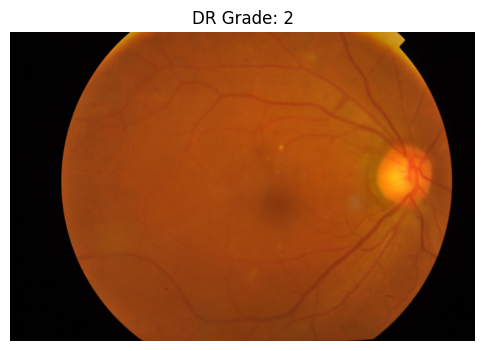

In [13]:
import matplotlib.pyplot as plt

image = Image.open(image_path)

plt.figure(figsize=(6, 6))
plt.imshow(image)
plt.axis("off")
plt.title(f"DR Grade: {label}")
plt.show()

In [14]:
import pandas as pd
import os

BASE_PATH = "/kaggle/input/datasets/mariaherrerot/aptos2019"

TRAIN_CSV = os.path.join(BASE_PATH, "train_1.csv")
VALID_CSV = os.path.join(BASE_PATH, "valid.csv")

TRAIN_DIR = os.path.join(BASE_PATH, "train_images", "train_images")
VALID_DIR = os.path.join(BASE_PATH, "val_images", "val_images")

train_df = pd.read_csv(TRAIN_CSV)
valid_df = pd.read_csv(VALID_CSV)

print("Training:", train_df.shape)
print("Validation:", valid_df.shape)

print("\nTraining distribution:")
print(train_df["diagnosis"].value_counts().sort_index())

print("\nValidation distribution:")
print(valid_df["diagnosis"].value_counts().sort_index())

Training: (2930, 2)
Validation: (366, 2)

Training distribution:
diagnosis
0    1434
1     300
2     808
3     154
4     234
Name: count, dtype: int64

Validation distribution:
diagnosis
0    172
1     40
2    104
3     22
4     28
Name: count, dtype: int64


In [15]:
import torch
from torch.utils.data import Dataset
from PIL import Image

class APTOSDataset(Dataset):

    def __init__(self, dataframe, image_dir, transform=None):
        self.dataframe = dataframe.reset_index(drop=True)
        self.image_dir = image_dir
        self.transform = transform

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):

        row = self.dataframe.iloc[index]

        image_id = row["id_code"]
        label = int(row["diagnosis"])

        image_path = os.path.join(
            self.image_dir,
            image_id + ".png"
        )

        image = Image.open(image_path).convert("RGB")

        if self.transform:
            image = self.transform(image)

        return image, label

In [16]:
from torchvision import transforms

train_transform = transforms.Compose([
    transforms.Resize((224, 224)),

    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(10),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

valid_transform = transforms.Compose([
    transforms.Resize((224, 224)),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

In [17]:
train_dataset = APTOSDataset(
    train_df,
    TRAIN_DIR,
    transform=train_transform
)

valid_dataset = APTOSDataset(
    valid_df,
    VALID_DIR,
    transform=valid_transform
)

print("Training images:", len(train_dataset))
print("Validation images:", len(valid_dataset))

Training images: 2930
Validation images: 366


In [18]:
from torch.utils.data import DataLoader

train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

valid_loader = DataLoader(
    valid_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

In [19]:
images, labels = next(iter(train_loader))

print("Image batch:", images.shape)
print("Label batch:", labels.shape)
print("Labels:", labels[:10])

Image batch: torch.Size([32, 3, 224, 224])
Label batch: torch.Size([32])
Labels: tensor([2, 2, 4, 0, 2, 1, 2, 0, 1, 2])


In [20]:
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Device: cuda
GPU: Tesla T4


In [21]:
import torch

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("CUDA version:", torch.version.cuda)

Device: cuda
GPU: Tesla T4
CUDA version: 12.8


In [22]:
import torch.nn as nn
from torchvision.models import efficientnet_b0, EfficientNet_B0_Weights

# Load ImageNet-pretrained EfficientNet-B0
weights = EfficientNet_B0_Weights.DEFAULT
model = efficientnet_b0(weights=weights)

# Replace the final classifier for 5 DR grades
num_features = model.classifier[1].in_features
model.classifier[1] = nn.Linear(num_features, 5)

# Move model to GPU
model = model.to(device)

print(model.classifier)

Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 144MB/s]


Sequential(
  (0): Dropout(p=0.2, inplace=True)
  (1): Linear(in_features=1280, out_features=5, bias=True)
)


In [23]:
nn.Linear(num_features, 5)

Linear(in_features=1280, out_features=5, bias=True)

In [24]:
print(next(model.parameters()).device)

cuda:0


In [25]:
import torch
import torch.nn as nn

# Count samples in each class
class_counts = train_df["diagnosis"].value_counts().sort_index()

print("Class counts:")
print(class_counts)

# Calculate inverse-frequency weights
class_weights = len(train_df) / (5 * torch.tensor(
    class_counts.values, dtype=torch.float
))

print("\nClass weights:")
print(class_weights)

Class counts:
diagnosis
0    1434
1     300
2     808
3     154
4     234
Name: count, dtype: int64

Class weights:
tensor([0.4086, 1.9533, 0.7252, 3.8052, 2.5043])


In [26]:
criterion = nn.CrossEntropyLoss(
    weight=class_weights.to(device)
)

print(criterion)

CrossEntropyLoss()


In [27]:
import torch.optim as optim

optimizer = optim.AdamW(
    model.parameters(),
    lr=1e-4,
    weight_decay=1e-4
)

print(optimizer)

AdamW (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: True
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.0001
    maximize: False
    weight_decay: 0.0001
)


In [28]:
model.train()

images, labels = next(iter(train_loader))

images = images.to(device)
labels = labels.to(device)

# Forward pass
outputs = model(images)

# Calculate loss
loss = criterion(outputs, labels)

# Backpropagation
optimizer.zero_grad()
loss.backward()
optimizer.step()

print("Output shape:", outputs.shape)
print("Loss:", loss.item())

Output shape: torch.Size([32, 5])
Loss: 1.5931832790374756


In [29]:
from sklearn.metrics import cohen_kappa_score, accuracy_score

In [30]:
def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()

    running_loss = 0.0
    all_preds = []
    all_labels = []

    for images, labels in loader:
        images = images.to(device)
        labels = labels.to(device)

        # Forward
        outputs = model(images)
        loss = criterion(outputs, labels)

        # Backward
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        # Statistics
        running_loss += loss.item() * images.size(0)

        preds = outputs.argmax(dim=1)

        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

    epoch_loss = running_loss / len(loader.dataset)

    accuracy = accuracy_score(all_labels, all_preds)

    qwk = cohen_kappa_score(
        all_labels,
        all_preds,
        weights="quadratic"
    )

    return epoch_loss, accuracy, qwk

In [31]:
def validate(model, loader, criterion, device):
    model.eval()

    running_loss = 0.0
    all_preds = []
    all_labels = []

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            running_loss += loss.item() * images.size(0)

            preds = outputs.argmax(dim=1)

            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    epoch_loss = running_loss / len(loader.dataset)

    accuracy = accuracy_score(all_labels, all_preds)

    qwk = cohen_kappa_score(
        all_labels,
        all_preds,
        weights="quadratic"
    )

    return epoch_loss, accuracy, qwk

In [33]:
num_epochs = 5

for epoch in range(num_epochs):

    train_loss, train_acc, train_qwk = train_one_epoch(
        model,
        train_loader,
        criterion,
        optimizer,
        device
    )

    val_loss, val_acc, val_qwk = validate(
        model,
        valid_loader,
        criterion,
        device
    )

    print(f"\nEpoch [{epoch+1}/{num_epochs}]")

    print(
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.4f} | "
        f"Train QWK: {train_qwk:.4f}"
    )

    print(
        f"Val Loss:   {val_loss:.4f} | "
        f"Val Acc:   {val_acc:.4f} | "
        f"Val QWK:   {val_qwk:.4f}"
    )


Epoch [1/5]
Train Loss: 0.6173 | Train Acc: 0.8201 | Train QWK: 0.8854
Val Loss:   0.7805 | Val Acc:   0.7951 | Val QWK:   0.8643

Epoch [2/5]
Train Loss: 0.5280 | Train Acc: 0.8382 | Train QWK: 0.9043
Val Loss:   0.8438 | Val Acc:   0.8033 | Val QWK:   0.8718

Epoch [3/5]
Train Loss: 0.4918 | Train Acc: 0.8567 | Train QWK: 0.9118
Val Loss:   0.8781 | Val Acc:   0.8224 | Val QWK:   0.8793

Epoch [4/5]
Train Loss: 0.3912 | Train Acc: 0.8857 | Train QWK: 0.9288
Val Loss:   0.9136 | Val Acc:   0.8306 | Val QWK:   0.8916

Epoch [5/5]
Train Loss: 0.3567 | Train Acc: 0.8887 | Train QWK: 0.9346
Val Loss:   0.9233 | Val Acc:   0.8279 | Val QWK:   0.8834


Confusion Matrix:
[[171   1   0   0   0]
 [  0  30   8   0   2]
 [  3  10  76   7   8]
 [  0   0   8   7   7]
 [  0   2   6   1  19]]


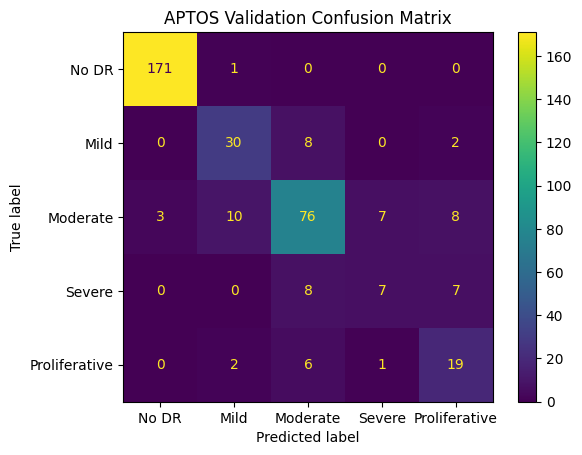

In [35]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

model.eval()

all_preds = []
all_labels = []

with torch.no_grad():
    for images, labels in valid_loader:
        images = images.to(device)

        outputs = model(images)
        preds = outputs.argmax(dim=1)

        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.numpy())

cm = confusion_matrix(all_labels, all_preds)

print("Confusion Matrix:")
print(cm)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=[
        "No DR",
        "Mild",
        "Moderate",
        "Severe",
        "Proliferative"
    ]
)

disp.plot()
plt.title("APTOS Validation Confusion Matrix")
plt.show()

In [36]:
torch.save({
    "model_state_dict": model.state_dict(),
    "optimizer_state_dict": optimizer.state_dict(),
    "epoch": 5,
    "val_qwk": 0.8739
}, "/kaggle/working/efficientnet_b0_aptos.pth")

print("Model saved.")

Model saved.


In [37]:
torch.save(
    model.state_dict(),
    "/kaggle/working/efficientnet_b0_baseline.pth"
)

print("Baseline model saved.")

Baseline model saved.


In [38]:
from PIL import Image
import torch

image_path = "/kaggle/input/datasets/mariaherrerot/aptos2019/train_images/train_images/200d947f75db.png"

image = Image.open(image_path).convert("RGB")
image = valid_transform(image).unsqueeze(0).to(device)

model.eval()

with torch.no_grad():
    output = model(image)
    diagnosis = output.argmax(dim=1).item()

print("Diagnosis:", diagnosis)
if(diagnosis == 0):
    print("No DR")
elif(diagnosis == 1):
    print("Mild NPDR")
elif(diagnosis == 2):
    print("Moderate NPDR")
elif(diagnosis == 3):
    print("Severe NPDR")
elif(diagnosis == 4):
    print("Proliferative DR")
else:
    print("Test again with clear image")

Diagnosis: 1
Mild NPDR


In [ ]:
import os

for root, dirs, files in os.walk("/kaggle/input"):
    print(root)

In [ ]:
DDR_ROOT = "/kaggle/input/datasets/mariaherrerot/ddrdataset/DR_grading/DR_grading"

import os

print("Contents:")
for item in os.listdir(DDR_ROOT):
    print(item)

In [ ]:
for root, dirs, files in os.walk(DDR_ROOT):
    print("\nFOLDER:", root)
    print("Subfolders:", dirs[:10])
    print("Files:", files[:10])

In [ ]:
import os

for root, dirs, files in os.walk(
    "/kaggle/input/datasets/mariaherrerot/ddrdataset"
):
    for file in files:
        if file.lower().endswith(".csv"):
            print(os.path.join(root, file))

In [39]:
DDR_CSV = "/kaggle/input/datasets/mariaherrerot/ddrdataset/DR_grading.csv"

import pandas as pd

ddr_df = pd.read_csv(DDR_CSV)

print(ddr_df.head())
print()
print("Shape:", ddr_df.shape)
print()
print("Columns:", ddr_df.columns.tolist())

                 id_code  diagnosis
0  20170413102628830.jpg          0
1  20170413111955404.jpg          0
2  20170413112015395.jpg          0
3  20170413112017305.jpg          0
4  20170413112528859.jpg          0

Shape: (12522, 2)

Columns: ['id_code', 'diagnosis']


In [40]:
print(
    ddr_df["diagnosis"]
    .value_counts()
    .sort_index()
)

diagnosis
0    6266
1     630
2    4477
3     236
4     913
Name: count, dtype: int64


In [41]:
DDR_IMAGE_DIR = "/kaggle/input/datasets/mariaherrerot/ddrdataset/DR_grading/DR_grading"

import os

missing = []

for image_id in ddr_df["id_code"]:
    image_path = os.path.join(DDR_IMAGE_DIR, image_id)

    if not os.path.exists(image_path):
        missing.append(image_id)

print("Total labels:", len(ddr_df))
print("Missing images:", len(missing))

if missing:
    print("First missing images:")
    print(missing[:10])
else:
    print("✓ Every CSV entry has a corresponding image!")

Total labels: 12522
Missing images: 0
✓ Every CSV entry has a corresponding image!


In [42]:
import os

for root, dirs, files in os.walk(
    "/kaggle/input/datasets/mariaherrerot/ddrdataset"
):
    for file in files:
        if file.lower().endswith(".csv"):
            print(os.path.join(root, file))

/kaggle/input/datasets/mariaherrerot/ddrdataset/DR_grading.csv


In [43]:
print(ddr_df.head())
print("Shape:", ddr_df.shape)
print("Columns:", ddr_df.columns.tolist())

print("\nDDR class distribution:")
print(ddr_df["diagnosis"].value_counts().sort_index())

                 id_code  diagnosis
0  20170413102628830.jpg          0
1  20170413111955404.jpg          0
2  20170413112015395.jpg          0
3  20170413112017305.jpg          0
4  20170413112528859.jpg          0
Shape: (12522, 2)
Columns: ['id_code', 'diagnosis']

DDR class distribution:
diagnosis
0    6266
1     630
2    4477
3     236
4     913
Name: count, dtype: int64


In [44]:
DDR_IMAGE_DIR = "/kaggle/input/datasets/mariaherrerot/ddrdataset/DR_grading/DR_grading"

ddr_df["image_path"] = ddr_df["id_code"].apply(
    lambda x: os.path.join(DDR_IMAGE_DIR, str(x))
)

print(ddr_df.head())

                 id_code  diagnosis  \
0  20170413102628830.jpg          0   
1  20170413111955404.jpg          0   
2  20170413112015395.jpg          0   
3  20170413112017305.jpg          0   
4  20170413112528859.jpg          0   

                                          image_path  
0  /kaggle/input/datasets/mariaherrerot/ddrdatase...  
1  /kaggle/input/datasets/mariaherrerot/ddrdatase...  
2  /kaggle/input/datasets/mariaherrerot/ddrdatase...  
3  /kaggle/input/datasets/mariaherrerot/ddrdatase...  
4  /kaggle/input/datasets/mariaherrerot/ddrdatase...  


In [45]:
from sklearn.model_selection import train_test_split

ddr_train_df, ddr_val_df = train_test_split(
    ddr_df,
    test_size=0.15,
    stratify=ddr_df["diagnosis"],
    random_state=42
)

print("DDR train:", len(ddr_train_df))
print("DDR validation:", len(ddr_val_df))

print("\nDDR train distribution:")
print(ddr_train_df["diagnosis"].value_counts().sort_index())

print("\nDDR validation distribution:")
print(ddr_val_df["diagnosis"].value_counts().sort_index())

DDR train: 10643
DDR validation: 1879

DDR train distribution:
diagnosis
0    5326
1     535
2    3805
3     201
4     776
Name: count, dtype: int64

DDR validation distribution:
diagnosis
0    940
1     95
2    672
3     35
4    137
Name: count, dtype: int64


In [49]:
class CombinedDRDataset(Dataset):
    def __init__(
        self,
        aptos_df=None,
        aptos_dir=None,
        ddr_df=None,
        transform=None
    ):
        self.transform = transform
        self.samples = []

        # APTOS
        if aptos_df is not None:
            for _, row in aptos_df.iterrows():
                image_path = os.path.join(
                    aptos_dir,
                    str(row["id_code"]) + ".png"
                )
                label = int(row["diagnosis"])
                self.samples.append((image_path, label))

        # DDR
        if ddr_df is not None:
            for _, row in ddr_df.iterrows():
                image_path = row["image_path"]
                label = int(row["diagnosis"])
                self.samples.append((image_path, label))

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, index):
        image_path, label = self.samples[index]

        image = Image.open(image_path).convert("RGB")

        if self.transform:
            image = self.transform(image)

        return image, label

In [50]:
combined_train_dataset = CombinedDRDataset(
    aptos_df=train_df,
    aptos_dir=TRAIN_DIR,
    ddr_df=ddr_train_df,
    transform=train_transform
)

combined_train_loader = DataLoader(
    combined_train_dataset,
    batch_size=32,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

print("Total training images:", len(combined_train_dataset))

Total training images: 13573


In [51]:
# Get all labels from the combined training dataset
combined_labels = [
    label for _, label in combined_train_dataset.samples
]

class_counts = pd.Series(combined_labels).value_counts().sort_index()

print("Combined class distribution:")
print(class_counts)

# Calculate balanced class weights
class_weights = len(combined_labels) / (
    5 * torch.tensor(class_counts.values, dtype=torch.float32)
)

print("\nClass weights:")
print(class_weights)

Combined class distribution:
0    6760
1     835
2    4613
3     355
4    1010
Name: count, dtype: int64

Class weights:
tensor([0.4016, 3.2510, 0.5885, 7.6468, 2.6877])


In [52]:
from torchvision.models import efficientnet_b0, EfficientNet_B0_Weights

weights = EfficientNet_B0_Weights.DEFAULT

model = efficientnet_b0(weights=weights)

num_features = model.classifier[1].in_features

model.classifier[1] = nn.Linear(
    num_features,
    5
)

model = model.to(device)

print("Model ready!")
print("Device:", device)

Model ready!
Device: cuda


In [53]:
criterion = nn.CrossEntropyLoss(
    weight=class_weights.to(device)
)

optimizer = optim.AdamW(
    model.parameters(),
    lr=1e-4,
    weight_decay=1e-4
)

print("Loss and optimizer ready!")

Loss and optimizer ready!


In [54]:
images, labels = next(iter(combined_train_loader))

images = images.to(device)
labels = labels.to(device)

outputs = model(images)

print("Images:", images.shape)
print("Labels:", labels.shape)
print("Outputs:", outputs.shape)

loss = criterion(outputs, labels)

print("Test loss:", loss.item())

Images: torch.Size([32, 3, 224, 224])
Labels: torch.Size([32])
Outputs: torch.Size([32, 5])
Test loss: 1.672587275505066


In [55]:
num_epochs = 5

best_qwk = -1.0
best_epoch = 0

for epoch in range(num_epochs):

    train_loss, train_acc, train_qwk = train_one_epoch(
        model,
        combined_train_loader,
        criterion,
        optimizer,
        device
    )

    val_loss, val_acc, val_qwk = validate(
        model,
        valid_loader,
        criterion,
        device
    )

    print(
        f"Epoch {epoch + 1}/{num_epochs} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.4f} | "
        f"Train QWK: {train_qwk:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.4f} | "
        f"Val QWK: {val_qwk:.4f}"
    )

    # Save the best model based on validation QWK
    if val_qwk > best_qwk:
        best_qwk = val_qwk
        best_epoch = epoch + 1

        torch.save(
            model.state_dict(),
            "/kaggle/working/efficientnet_b0_aptos_ddr_best.pth"
        )

        print(f"  ✓ New best model saved! QWK = {best_qwk:.4f}")

Epoch 1/5 | Train Loss: 1.1239 | Train Acc: 0.5563 | Train QWK: 0.6112 | Val Loss: 1.0795 | Val Acc: 0.7049 | Val QWK: 0.8116
  ✓ New best model saved! QWK = 0.8116
Epoch 2/5 | Train Loss: 0.8296 | Train Acc: 0.6782 | Train QWK: 0.7667 | Val Loss: 0.9719 | Val Acc: 0.6940 | Val QWK: 0.8360
  ✓ New best model saved! QWK = 0.8360
Epoch 3/5 | Train Loss: 0.7024 | Train Acc: 0.7194 | Train QWK: 0.8024 | Val Loss: 1.3317 | Val Acc: 0.6940 | Val QWK: 0.8182
Epoch 4/5 | Train Loss: 0.6374 | Train Acc: 0.7359 | Train QWK: 0.8243 | Val Loss: 0.8930 | Val Acc: 0.7814 | Val QWK: 0.8880
  ✓ New best model saved! QWK = 0.8880
Epoch 5/5 | Train Loss: 0.5530 | Train Acc: 0.7689 | Train QWK: 0.8426 | Val Loss: 0.8297 | Val Acc: 0.8005 | Val QWK: 0.8863


In [56]:
print("Best epoch:", best_epoch)
print("Best validation QWK:", best_qwk)

Best epoch: 4
Best validation QWK: 0.8879706152433425


In [57]:
best_model_path = "/kaggle/working/efficientnet_b0_aptos_ddr_best.pth"

model.load_state_dict(
    torch.load(best_model_path, map_location=device)
)

model = model.to(device)
model.eval()

print("✓ Best model loaded")
print("Best validation QWK:", best_qwk)

✓ Best model loaded
Best validation QWK: 0.8879706152433425


In [58]:
from sklearn.metrics import confusion_matrix, classification_report
import numpy as np

model.eval()

all_preds = []
all_labels = []

with torch.no_grad():
    for images, labels in valid_loader:
        images = images.to(device)

        outputs = model(images)
        preds = outputs.argmax(dim=1)

        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.numpy())

cm = confusion_matrix(all_labels, all_preds)

print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[171   1   0   0   0]
 [  2  31   4   2   1]
 [  0  20  57  21   6]
 [  0   0   5  12   5]
 [  0   2   4   7  15]]


In [59]:
class_names = [
    "No DR",
    "Mild DR",
    "Moderate DR",
    "Severe DR",
    "Proliferative DR"
]

print(
    classification_report(
        all_labels,
        all_preds,
        target_names=class_names,
        digits=4,
        zero_division=0
    )
)

                  precision    recall  f1-score   support

           No DR     0.9884    0.9942    0.9913       172
         Mild DR     0.5741    0.7750    0.6596        40
     Moderate DR     0.8143    0.5481    0.6552       104
       Severe DR     0.2857    0.5455    0.3750        22
Proliferative DR     0.5556    0.5357    0.5455        28

        accuracy                         0.7814       366
       macro avg     0.6436    0.6797    0.6453       366
    weighted avg     0.8183    0.7814    0.7884       366



In [60]:
import os

print(os.path.exists(
    "/kaggle/working/efficientnet_b0_aptos_ddr_best.pth"
))

True


In [62]:
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image

In [64]:
def generate_gradcam(model, image_tensor, target_class=None):
    model.eval()

    activations = None
    gradients = None

    # EfficientNet-B0's final convolutional feature layer
    target_layer = model.features[-1]

    def forward_hook(module, input, output):
        nonlocal activations
        activations = output

    def backward_hook(module, grad_input, grad_output):
        nonlocal gradients
        gradients = grad_output[0]

    forward_handle = target_layer.register_forward_hook(forward_hook)
    backward_handle = target_layer.register_full_backward_hook(backward_hook)

    # Forward pass
    output = model(image_tensor)

    probabilities = torch.softmax(output, dim=1)

    if target_class is None:
        target_class = output.argmax(dim=1).item()

    # Clear gradients
    model.zero_grad()

    # Backpropagate the selected class
    score = output[0, target_class]
    score.backward()

    # Remove hooks
    forward_handle.remove()
    backward_handle.remove()

    # Global average pooling of gradients
    weights = gradients.mean(dim=(2, 3), keepdim=True)

    # Weighted combination of activation maps
    cam = (weights * activations).sum(dim=1, keepdim=True)

    # ReLU: only positive influence
    cam = F.relu(cam)

    # Resize to input image size
    cam = F.interpolate(
        cam,
        size=(224, 224),
        mode="bilinear",
        align_corners=False
    )

    # Normalize
    cam = cam.squeeze().detach().cpu().numpy()

    cam -= cam.min()

    if cam.max() > 0:
        cam /= cam.max()

    return cam, target_class, probabilities[0].detach().cpu().numpy()

In [65]:
image_path = os.path.join(
    VALID_DIR,
    valid_df.iloc[0]["id_code"] + ".png"
)

print("Image:", image_path)
print("Actual class:", valid_df.iloc[0]["diagnosis"])

Image: /kaggle/input/datasets/mariaherrerot/aptos2019/val_images/val_images/000c1434d8d7.png
Actual class: 2


In [66]:
image = Image.open(image_path).convert("RGB")

image_tensor = valid_transform(image).unsqueeze(0).to(device)

cam, predicted_class, probabilities = generate_gradcam(
    model,
    image_tensor
)

print("Predicted class:", predicted_class)
print("Confidence:", probabilities[predicted_class])

Predicted class: 2
Confidence: 0.71628106


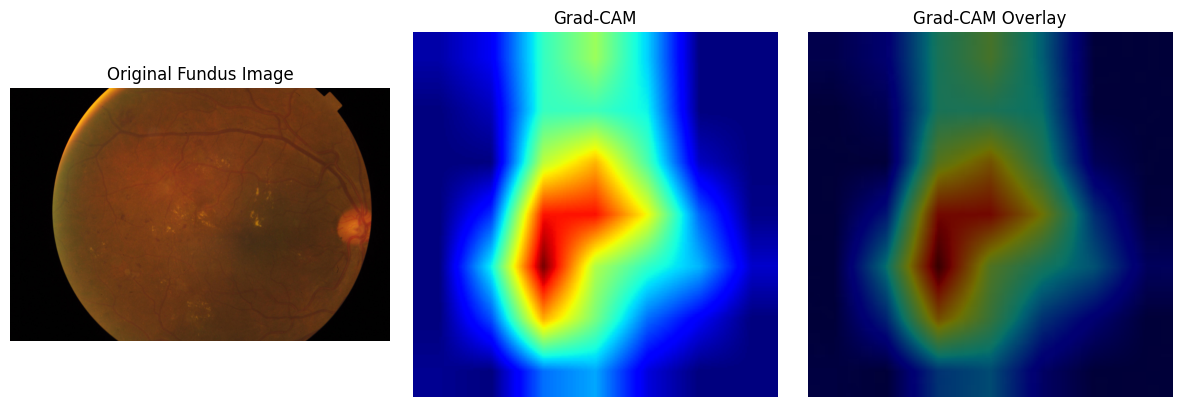

In [67]:
plt.figure(figsize=(12, 4))

# Original image
plt.subplot(1, 3, 1)
plt.imshow(image)
plt.title("Original Fundus Image")
plt.axis("off")

# Grad-CAM
plt.subplot(1, 3, 2)
plt.imshow(cam, cmap="jet")
plt.title("Grad-CAM")
plt.axis("off")

# Overlay
plt.subplot(1, 3, 3)
plt.imshow(image)
plt.imshow(cam, cmap="jet", alpha=0.45)
plt.title("Grad-CAM Overlay")
plt.axis("off")

plt.tight_layout()
plt.show()

In [68]:
from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

# Convert 5-class labels into binary screening labels
# 0/1 = non-referable
# 2/3/4 = referable

binary_labels = [
    1 if label >= 2 else 0
    for label in all_labels
]

binary_preds = [
    1 if pred >= 2 else 0
    for pred in all_preds
]

print("Binary confusion matrix:")
print(confusion_matrix(binary_labels, binary_preds))

print("\nAccuracy:",
      accuracy_score(binary_labels, binary_preds))

print("Sensitivity / Recall:",
      recall_score(binary_labels, binary_preds))

print("Precision:",
      precision_score(binary_labels, binary_preds))

print("F1:",
      f1_score(binary_labels, binary_preds))

print("\nClassification report:")
print(
    classification_report(
        binary_labels,
        binary_preds,
        target_names=["Non-referable", "Referable"],
        digits=4
    )
)

Binary confusion matrix:
[[205   7]
 [ 22 132]]

Accuracy: 0.9207650273224044
Sensitivity / Recall: 0.8571428571428571
Precision: 0.9496402877697842
F1: 0.9010238907849829

Classification report:
               precision    recall  f1-score   support

Non-referable     0.9031    0.9670    0.9339       212
    Referable     0.9496    0.8571    0.9010       154

     accuracy                         0.9208       366
    macro avg     0.9264    0.9121    0.9175       366
 weighted avg     0.9227    0.9208    0.9201       366



In [69]:
def predict_dr(image_path):
    image = Image.open(image_path).convert("RGB")

    image_tensor = valid_transform(image).unsqueeze(0).to(device)

    model.eval()

    with torch.no_grad():
        output = model(image_tensor)
        probabilities = torch.softmax(output, dim=1)

    predicted_class = output.argmax(dim=1).item()
    confidence = probabilities[0, predicted_class].item()

    if predicted_class >= 2:
        screening_status = "Referable DR"
    else:
        screening_status = "Non-referable DR"

    return {
        "image": image,
        "predicted_class": predicted_class,
        "diagnosis": class_names[predicted_class],
        "confidence": confidence,
        "screening_status": screening_status,
        "probabilities": probabilities[0].cpu().numpy()
    }

In [70]:
result = predict_dr(image_path)

print("Diagnosis:", result["diagnosis"])
print("Confidence:", f"{result['confidence']:.2%}")
print("Screening status:", result["screening_status"])

Diagnosis: Moderate DR
Confidence: 71.63%
Screening status: Referable DR


In [72]:
def show_explanation(image_path):

    result = predict_dr(image_path)

    image = result["image"]

    image_tensor = valid_transform(image).unsqueeze(0).to(device)

    cam, predicted_class, probabilities = generate_gradcam(
        model,
        image_tensor
    )

    plt.figure(figsize=(15, 5))

    plt.subplot(1, 3, 1)
    plt.imshow(image)
    plt.title("Fundus Image")
    plt.axis("off")

    plt.subplot(1, 3, 2)
    plt.imshow(cam, cmap="jet")
    plt.title("Grad-CAM")
    plt.axis("off")

    plt.subplot(1, 3, 3)
    plt.imshow(image)
    plt.imshow(cam, cmap="jet", alpha=0.45)
    plt.title(
        f"{result['diagnosis']}\n"
        f"Confidence: {result['confidence']:.1%}\n"
        f"{result['screening_status']}"
    )
    plt.axis("off")

    plt.tight_layout()
    plt.show()

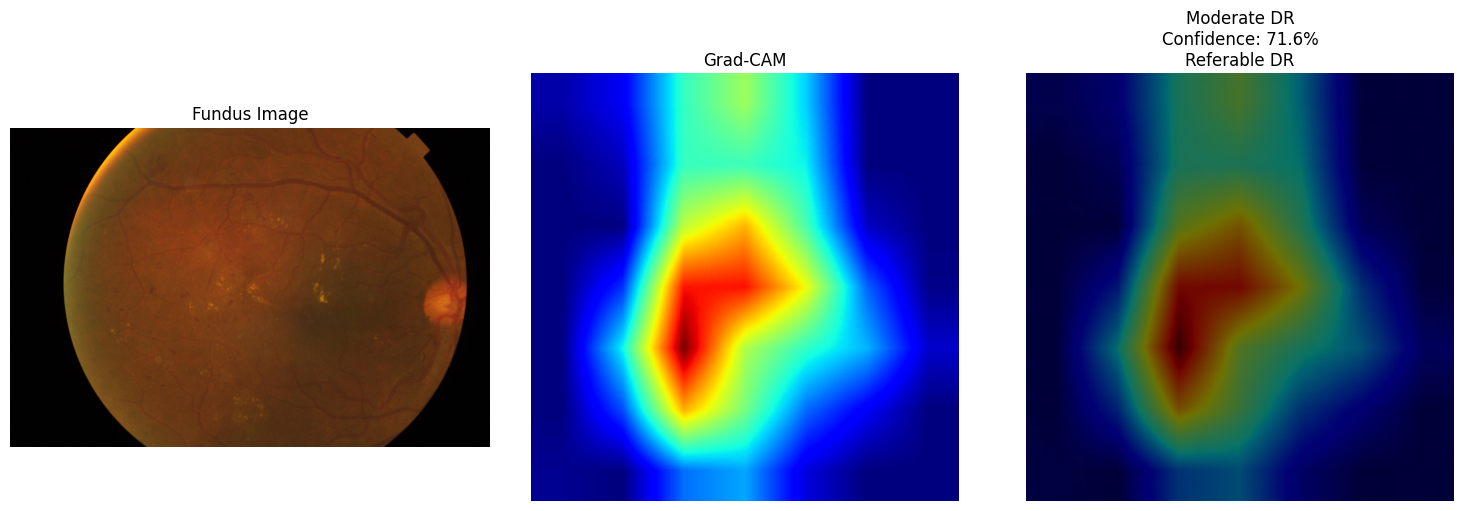

In [73]:
show_explanation(image_path)